# Project 1

## Overview

In this project, you will build models that classify news articles by topic. You will represent each article with TF-IDF features (see 4) and train two classifiers introduced in this module: logistic regression and a multilayer perceptron (MLP). Transformers and pretrained language models are outside the scope of this project.

You will investigate whether models trained on one news dataset generalize to unseen in-domain articles, transfer to articles collected from a different source, and adapt when category definitions change. You will also study how regularization and limited target-domain training data affect performance.

Key concepts of this project include:
- construct a reproducible text-classification pipeline without evaluation-data leakage;
- compare a linear classifier with a nonlinear neural-network classifier;
- select hyperparameters using validation data and appropriate evaluation metrics;
- analyze in-domain performance, cross-dataset transfer, and category mismatch; and
- support quantitative results with error analysis and clear explanations.


### Dependencies & Notebook Configurations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

In [2]:
# for reproducibility
np.random.seed(0)
torch.manual_seed(0)

## Data Load & Preprocessing

In [3]:
source_a_train = pd.read_csv("./dataset/dataset_a_train.csv")
source_a_test = pd.read_csv("./dataset/dataset_a_test.csv")

display(source_a_train.head())
display(source_a_test.head())

source_b_test = pd.read_csv("./dataset/dataset_b_test.csv")

display(source_b_test.head())

source_c_train = pd.read_csv("./dataset/dataset_c_train.csv")
source_c_test = pd.read_csv("./dataset/dataset_c_test.csv")

display(source_c_train.head())
display(source_c_test.head())

,Label,Title,Description
0,3,Huge California Gas Leak Will Come To An End I...,A relief well that the company began drilling ...
1,3,TheFuturein5 Episode 25: Why This Time It's Di...,"As the saying goes, ""Either you disrupt or get..."
2,3,Enough About Disruption: We're in the Golden A...,Those not plunging into the brave new world on...
3,3,Mind Your Manners Tips for Effective Cross-Cul...,Communicating across cultures in the business ...
4,3,Uber Refunds Fares After Uproar Over London Te...,Prices soared as people scrambled to flee the ...


,Label,Title,Description
0,4,Police Officials Tell Congress Encryption Hurt...,The encryption debate returned to Congress on ...
1,2,Wisconsin Apologizes For Mishandling Fans Depi...,“We will learn from this incident and do bette...
2,2,Karl-Anthony Towns Carves His Own Path As The ...,The Minnesota center is a playmaking 7-footer ...
3,2,High School Basketball Player Pulls Off Jaw-Dr...,"Tyler Williams said he wanted to ""spice up"" th..."
4,3,"Toys R Us May Shut Down All U.S. Operations, I...","The liquidation could put up to 33,000 U.S. jo..."


,Label,Title,Description
0,3,Crossrail link 'to get go-ahead',"The £10bn Crossrail transport plan, backed by..."
1,5,Uganda bans Vagina Monologues,Uganda's authorities have banned the play The...
2,1,Campaign 'cold calls' questioned,Labour and the Conservatives are still teleph...
3,4,US peer-to-peer pirates convicted,The first convictions for piracy over peer-to...
4,2,Moyes U-turn on Beattie dismissal,Everton manager David Moyes will discipline s...


,Label,Title,Description
0,1,US eyes cut in troops in Afghanistan,"KABUL, Afghanistan -- The United States could ..."
1,1,"Soldier, 4 Militants Die in Renewed Gaza Fighting",GAZA (Reuters) - Four Palestinian militants a...
2,1,Brazilian Soldier Wounded in Haiti Unrest,A Brazilian soldier with the UN peacekeeping f...
3,1,"Iraq Bombings Kill 35 Youths, Hurt Scores (AP)",AP - A string of bombs killed 35 children and ...
4,1,Airstrike said to kill 50 at suspected Qaeda site,PAKISTAN WANA -- Pakistani warplanes pummeled ...


,Label,Title,Description
0,4,New Internet magazine grooms women for jihad,DUBAI: quot;Our main mission: push our childr...
1,2,Race driver killed in crash,Race car driver Tommy Baldwin was killed in a ...
2,1,Aid Group Threatens Afghanistan Pullout,An aid group in Afghanistan said it was consid...
3,4,Protests target nuclear shipment,Protests continue in France in a bid to stop d...
4,1,Fidel Castro Greets Venezuela's Chavez (AP),AP - Fidel Castro appears to be recovering wel...


In [4]:
labels = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set B": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set C": ["World", "Sports", "Business", "Technology", None]
}).set_index("Label")

display(labels)

,Set A,Set B,Set C
Label,,,
1,Politics,Politics,World
2,Sports,Sports,Sports
3,Business,Business,Business
4,Technology,Technology,Technology
5,Entertainment,Entertainment,NaN


_Note_: Labels 2, 3, and 4 have matching meanings across all three datasets. Label 1 does not: Politics in Data A and Data B is narrower than World in Data C. A political story may reasonably belong to the World category, but World also includes international events whose main topic is not politics. Data C also has no label 5.

## Part 2: Build an In-Domain Baseline on Data A

### Build a TF-IDF Table

In [5]:
a_train, a_val = train_test_split(source_a_train, test_size=0.2, random_state=0)

print(source_a_train.shape)
display(a_train)
display(a_val)

(7500, 3)


,Label,Title,Description
1328,3,Confession: I Loved My Onboarding Experience,It's been over a year and a half since I joine...
2368,5,Jeff Goldblum To Reprise Role In 'Jurassic Wor...,He's back!
4113,1,Republicans Don’t Own The Supreme Court,"From 1968 through 1988, Republican candidates ..."
1670,5,You Won't Believe Where The Chanels Ended Up I...,"We're back, idiot hookers."
2364,5,James Corden Prods Jennifer Lopez To Dish On A...,"""Please don't do this."""
...,...,...,...
4931,2,Utah May Name Its New Pro Football Team 'Teamy...,The Internet is undefeated.
3264,1,These Women Are Marching Because The Man They ...,Politics is personal for some of the women pro...
1653,5,Adele Would Like You To Enjoy Her Concerts IRL...,🎤 Recording in the de-e-e-p. 🎤
2607,5,Kimmel Exposes Biggest Anti-Vaxxer 'Pandummies...,The late-night host called these people corona...


,Label,Title,Description
1563,5,Beyoncé Fans Are In A Panic Over Their Already...,"Hey, at least you can always sell them."
5333,2,Now LeBron James Is Helping Ohio Parents Get T...,His new partnership covers test fees and provi...
7424,4,Windows 8 Vocabulary Terms You Need To Talk In...,"Quickness -- (We cheated on 'Q', sue us.) Micr..."
6731,4,These Are The States That Would Rather Learn A...,There are way more of them than you'd think.
4178,1,Trump And Clinton On Guns: Two Visions Of Race...,"For years seen as a losing battle, the push fo..."
...,...,...,...
3188,1,Madison Cawthorn Destroyed On Twitter For Cele...,"""If you wanted to take credit for it, you prob..."
5770,2,One Of Hip-Hop's Greatest Sports Mysteries Has...,"No, not that one, but it's still pretty good."
2095,5,Selena Gomez Is So Sultry Performing 'Same Old...,"Sexy, sultry and stunning."
20,3,8 Ways To Get People To Take You More Seriously,If you really want to be taken more seriously ...


In [6]:
vectorizer = TfidfVectorizer()  # default ngram_range is unigram

a_train_tfidf = vectorizer.fit_transform(a_train["Title"] + ' ' + a_train["Description"])
a_val_tfidf = vectorizer.transform(a_val["Title"] + ' ' + a_val["Description"])

a_train_tensor = torch.tensor(a_train_tfidf.toarray(), dtype=torch.float32)
a_val_tensor = torch.tensor(a_val_tfidf.toarray(), dtype=torch.float32)
print(a_train_tensor)
print(a_val_tensor)

# CrossEntropyLoss expects zero-indexed labels, so label - 1
a_train_labels_tensor = torch.tensor((a_train["Label"] - 1).to_list(), dtype=torch.long)
a_val_labels_tensor = torch.tensor((a_val["Label"] - 1).to_list(), dtype=torch.long)
print(a_train_labels_tensor)
print(a_val_labels_tensor)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
tensor([2, 4, 0,  ..., 4, 4, 4])
tensor([4, 1, 3,  ..., 4, 2, 1])


### Logistic Regressor

In [7]:
# Constants & Hyperparameters
MAX_EPOCH = 50  # TODO: maybe we can do some early stopping during the training process
LEARNING_RATE = 0.01

In [8]:
model = torch.nn.Linear(a_train_tensor.shape[1], labels.shape[0])

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

In [9]:
# TODO: Convert this into a function so we don't need to write down the whole bloody lines of code every single time we update it
# TODO: Support using GPU if available
train_losses = []
validation_losses = []

for epoch in range(MAX_EPOCH):
    print(f"Epoch: {epoch + 1:02}/{MAX_EPOCH}", end='')
    # Training
    model.train()

    train_loss = 0  # compute the cumulative loss within an epoch

    for i, (x, y) in enumerate(zip(a_train_tensor, a_train_labels_tensor)):
        logits = model(x)

        loss = criterion(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(a_train_tensor)
    train_losses.append(train_loss)

    # Validation
    model.eval()

    validation_loss = 0  # same as train

    with torch.inference_mode():
        for i, (x, y) in enumerate(zip(a_val_tensor, a_val_labels_tensor)):
            logits = model(x)

            loss = criterion(logits, y)

            validation_loss += loss.item()

    validation_loss /= len(a_val_tensor)

    validation_losses.append(validation_loss)

    print("\tDone!")

Epoch: 01/50	Done!
Epoch: 02/50	Done!
Epoch: 03/50	Done!
Epoch: 04/50	Done!
Epoch: 05/50	Done!
Epoch: 06/50	Done!
Epoch: 07/50	Done!
Epoch: 08/50	Done!
Epoch: 09/50	Done!
Epoch: 10/50	Done!
Epoch: 11/50	Done!
Epoch: 12/50	Done!
Epoch: 13/50	Done!
Epoch: 14/50	Done!
Epoch: 15/50	Done!
Epoch: 16/50	Done!
Epoch: 17/50	Done!
Epoch: 18/50	Done!
Epoch: 19/50	Done!
Epoch: 20/50	Done!
Epoch: 21/50	Done!
Epoch: 22/50	Done!
Epoch: 23/50	Done!
Epoch: 24/50	Done!
Epoch: 25/50	Done!
Epoch: 26/50	Done!
Epoch: 27/50	Done!
Epoch: 28/50	Done!
Epoch: 29/50	Done!
Epoch: 30/50	Done!
Epoch: 31/50	Done!
Epoch: 32/50	Done!
Epoch: 33/50	Done!
Epoch: 34/50	Done!
Epoch: 35/50	Done!
Epoch: 36/50	Done!
Epoch: 37/50	Done!
Epoch: 38/50	Done!
Epoch: 39/50	Done!
Epoch: 40/50	Done!
Epoch: 41/50	Done!
Epoch: 42/50	Done!
Epoch: 43/50	Done!
Epoch: 44/50	Done!
Epoch: 45/50	Done!
Epoch: 46/50	Done!
Epoch: 47/50	Done!
Epoch: 48/50	Done!
Epoch: 49/50	Done!
Epoch: 50/50	Done!


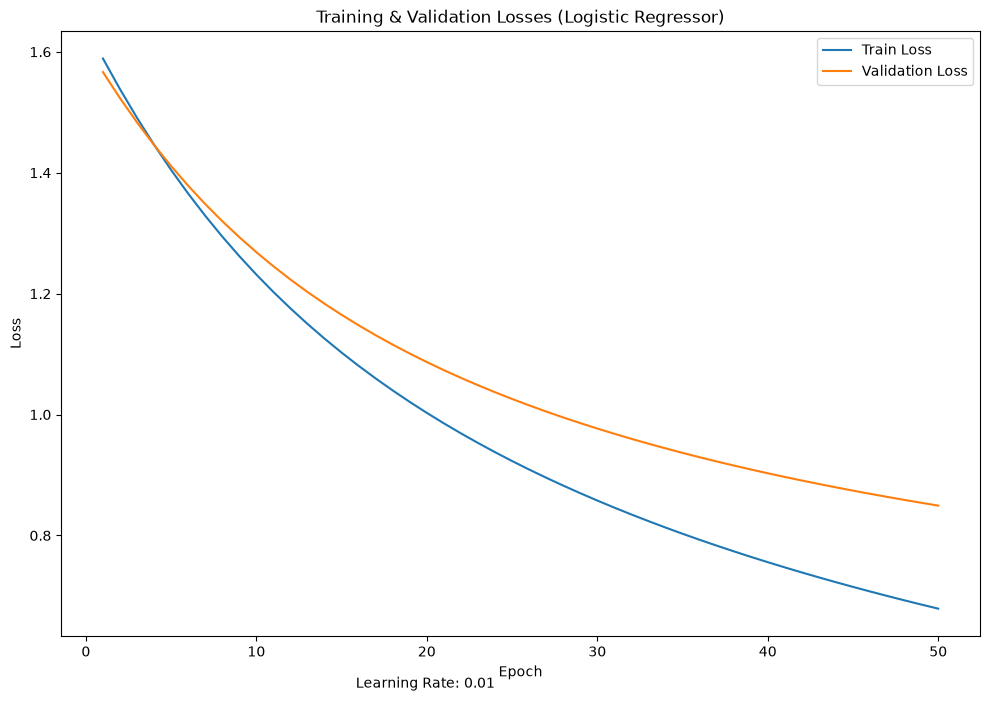

In [10]:
plt.figure(figsize=(10, 7))

EPOCHS = range(1, MAX_EPOCH + 1)

plt.plot(EPOCHS, train_losses, label="Train Loss")
plt.plot(EPOCHS, validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training & Validation Losses (Logistic Regressor)")

plt.figtext(0.5, 0.01, f"Learning Rate: {LEARNING_RATE}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

### Custom Multi-Layer Perceptron

In [11]:
class CustomMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.layers = nn.Sequential(
            # TODO: consider adding dropout for Part 3 ig
            nn.Linear(input_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.layers(x)

In [12]:
# Constants & Hyperparameters
MAX_EPOCH = 20
lEARNING_RATE = 0.01

In [13]:
model = CustomMLP(a_train_tensor.shape[1], labels.shape[0])

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

In [14]:
train_losses = []
validation_losses = []

for epoch in range(MAX_EPOCH):
    print(f"Epoch: {epoch + 1:02}/{MAX_EPOCH}", end='')
    # Training
    model.train()

    train_loss = 0  # compute the cumulative loss within an epoch

    for i, (x, y) in enumerate(zip(a_train_tensor, a_train_labels_tensor)):
        logits = model(x)

        loss = criterion(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(a_train_tensor)
    train_losses.append(train_loss)

    # Validation
    model.eval()

    validation_loss = 0  # same as train

    with torch.inference_mode():
        for i, (x, y) in enumerate(zip(a_val_tensor, a_val_labels_tensor)):
            logits = model(x)

            loss = criterion(logits, y)

            validation_loss += loss.item()

    validation_loss /= len(a_val_tensor)

    validation_losses.append(validation_loss)

    print("\tDone!")

Epoch: 01/20	Done!
Epoch: 02/20	Done!
Epoch: 03/20	Done!
Epoch: 04/20	Done!
Epoch: 05/20	Done!
Epoch: 06/20	Done!
Epoch: 07/20	Done!
Epoch: 08/20	Done!
Epoch: 09/20	Done!
Epoch: 10/20	Done!
Epoch: 11/20	Done!
Epoch: 12/20	Done!
Epoch: 13/20	Done!
Epoch: 14/20	Done!
Epoch: 15/20	Done!
Epoch: 16/20	Done!
Epoch: 17/20	Done!
Epoch: 18/20	Done!
Epoch: 19/20	Done!
Epoch: 20/20	Done!
